# Figure 3a. Overlap of cis-eGene, trans-eGene, trans-eProgram and trans-biomarker loci

UpSet plot of independent colocalized loci (merged ColocBoost colocalization sets, CoS). Each locus is assigned to cis-eGene, trans-eGene, trans-eProgram and/or trans-biomarker (protein, glycoprotein or metabolite QTL) according to the traits it colocalizes with. Loci are kept if they colocalize with a cis-eGene, or with both a trans-eQTL (eGene or eProgram) and a trans-biomarker. Top bars show the number of loci in each exact combination (sorted by size); right bars show the total number of loci per category. This is a descriptive count; no statistical test is involved.

Input: `data/Figure_3a_upset_loci.rds`

In [1]:
suppressPackageStartupMessages({
  library(ggplot2)
  library(ComplexUpset)
})
loci <- readRDS("data/Figure_3a_upset_loci.rds")
dim(loci)
head(loci)
colSums(loci[, -1])

[1] 60842     5

,locus_id,cis_eGene,trans_eGene,trans_eProgram,trans_biomarker
,<chr>,<lgl>,<lgl>,<lgl>,<lgl>
1,ind_cos_1,TRUE,TRUE,FALSE,FALSE
2,ind_cos_2,TRUE,TRUE,TRUE,TRUE
3,ind_cos_3,TRUE,FALSE,FALSE,FALSE
4,ind_cos_4,TRUE,TRUE,FALSE,FALSE
5,ind_cos_5,TRUE,TRUE,FALSE,FALSE
6,ind_cos_6,TRUE,TRUE,TRUE,TRUE


cis_eGene     trans_eGene  trans_eProgram trans_biomarker 
          15435           43011           29811           47334

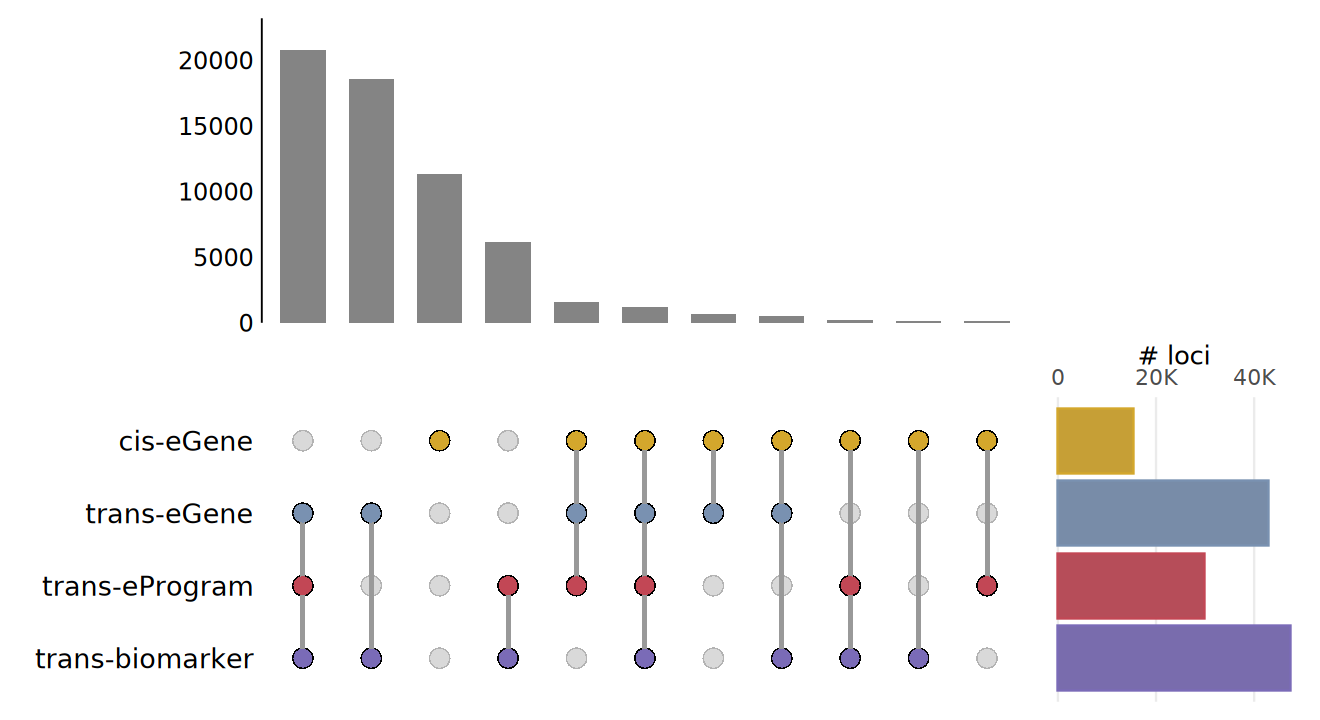

In [2]:
set_display <- c(cis_eGene = "cis-eGene", trans_eGene = "trans-eGene",
                 trans_eProgram = "trans-eProgram", trans_biomarker = "trans-biomarker")
names(loci)[match(names(set_display), names(loci))] <- set_display

set_colors <- c("cis-eGene" = "#D4A72C", "trans-eGene" = "#7991B1",
                "trans-eProgram" = "#C24755", "trans-biomarker" = "#7A6BB7")

p <- upset(
  loci, rev(unname(set_display)),
  name = NULL, width_ratio = 0.25, height_ratio = c(1, 2),
  sort_sets = FALSE, sort_intersections = "descending",
  queries = lapply(unname(set_display), function(s)
    upset_query(set = s, fill = set_colors[[s]], color = set_colors[[s]])),
  set_sizes = upset_set_size(geom = geom_bar(alpha = 0.85), position = "right") +
    scale_y_continuous(breaks = c(0, 20000, 40000), labels = c("0", "20K", "40K"), position = "right") +
    labs(y = "# loci") +
    theme(axis.text.x = element_text(size = 13), axis.title.x = element_text(size = 15),
          panel.grid.major.y = element_blank(), panel.grid.minor = element_blank()),
  base_annotations = list(
    " " = intersection_size(width = 0.65, text = list(size = 0, alpha = 0), alpha = 0.85, fill = "#6F6F6F") +
      scale_y_continuous(expand = expansion(mult = c(0, 0.12))) +
      labs(y = NULL) +
      theme(axis.text.y = element_text(size = 14, color = "black"),
            panel.grid = element_blank(),
            axis.line.y = element_line(linewidth = 0.4, color = "black"))
  ),
  matrix = intersection_matrix(
    geom = geom_point(shape = 16, size = 5, stroke = 0),
    segment = geom_segment(linewidth = 1, color = "grey60")
  ),
  stripes = upset_stripes(geom = geom_segment(linewidth = 0), colors = c("white", "white")),
  themes = upset_modify_themes(list(
    "intersections_matrix" = theme(axis.text.y = element_text(size = 16, color = "black"),
                                   panel.grid = element_blank())
  ))
)

options(repr.plot.width = 11, repr.plot.height = 6)
p